# Smart Vitals 02: comparing approaches (Output 1)
**CMS22301 · Smart Vitals IPMS**

Notebook 01 trained one random forest on our simulator data and reached **recall for Critical 0.62**, far below the target of **0.90** (assumption A5). It also showed why: the model was not told each patient's **SpO₂ scale**, so an SpO₂ of 90% looked normal for some patients and critical for others.

This notebook compares several approaches **on the same 16 unseen patients**, so the comparison is fair:

| Approach | Learns? | Idea |
|---|---|---|
| NEWS2-inspired rule on the reading | no | apply our labelling rule directly to the noisy reading |
| NEWS2-inspired rule on the last-5 median | no | the same rule, on a short median that smooths sensor noise |
| Logistic regression | yes | straight-line boundaries |
| Random forest | yes | many trees that vote (as notebook 01, but trees stop at 20 readings per leaf) |
| Gradient boosting | yes | trees built one after another, each fixing the last one's mistakes |

Each learning model is tried with two sets of inputs: **the single reading** and **the reading plus the median of the last 5 readings** ("readings or sequences?" at the end of notebook 01).

**How the threshold is chosen without peeking at the test patients.** Each model gives a probability of Critical. We call a reading Critical when that probability passes a threshold. The threshold is tuned with **5-fold cross-validation grouped by patient on the training patients only**: the lowest number of false alarms that still finds 92% of Critical readings (a small margin above the 0.90 target, because new patients differ). The test patients are used once, at the end.

No real patient data is used: everything comes from `simulator/` (see `data/DATA_CARD.md`).

## Setup

In [1]:
from pathlib import Path
import io
import json
import sys
import time
from datetime import date

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
from sklearn.model_selection import GroupKFold, GroupShuffleSplit
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.evaluation import critical_threshold_for_recall, scores
from src.features import SINGLE_FEATURES, WINDOW, WINDOW_FEATURES, add_patient_settings, add_window_features, clean_readings
from src.labelling import LABELS, label
from src.model import predict_with_threshold

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
SEED = 42
RECALL_TARGET = 0.90      # assumption A5
TUNING_TARGET = 0.92      # what thresholds are tuned to on the training patients (a margin above A5)
FALSE_ALARM_CAP = 5       # per 100 Normal readings (A5)
print("Project folder:", ROOT)

Project folder: /Users/mdmasudrana/Downloads/smart-vitals


## Step 1 · Load, clean and prepare the readings
`clean_readings` does what the API will do with every message (R9): keep only the first copy of a duplicated message, and treat an impossible value (for example a heart rate of 250) as missing rather than as a patient getting worse. `add_patient_settings` adds each patient's SpO₂ scale, which the API knows from the patient record. `add_window_features` adds the median of each vital over the current and previous four readings of the same patient.

The ground-truth file is joined **only to break the results down afterwards** (by fault and episode type). It is never a model input.

In [2]:
vitals = pd.read_csv(ROOT / "data" / "sim_vitals.csv")
patients = pd.read_csv(ROOT / "data" / "sim_patients.csv")
truth = pd.read_csv(ROOT / "data" / "sim_ground_truth.csv", usecols=["msg_id", "fault_type", "episode_type"])

df, cleaning = clean_readings(vitals)
df = add_window_features(add_patient_settings(df, patients))
df = df.merge(truth, on="msg_id", how="left")
print(f"Delivered messages: {len(vitals):,} -> readings after cleaning: {len(df):,}")
print("Cleaning:", {k: v for k, v in cleaning.items() if v})
print("Labels:", df["status"].value_counts(normalize=True).round(3).to_dict())

Delivered messages: 346,418 -> readings after cleaning: 342,931
Cleaning: {'duplicates_dropped': 3487, 'impossible_heart_rate': 196, 'impossible_spo2': 200, 'impossible_systolic_bp': 204, 'impossible_diastolic_bp': 194, 'impossible_temperature': 205, 'impossible_glucose': 64}
Labels: {'Normal': 0.939, 'Critical': 0.044, 'Warning': 0.017}


## Step 2 · The same unseen patients as notebook 01
`GroupShuffleSplit` with the same seed picks the same 16 test patients as notebook 01, so the numbers can be compared directly.

In [3]:
learn_idx, test_idx = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED)
                           .split(df, df["status"], groups=df["patient_id"]))
learn, test = df.iloc[learn_idx].reset_index(drop=True), df.iloc[test_idx].reset_index(drop=True)
print(f"Training: {learn['patient_id'].nunique()} patients, {len(learn):,} readings")
print(f"Test:     {test['patient_id'].nunique()} patients, {len(test):,} readings")
print("Test patients:", sorted(test["patient_id"].unique()))

Training: 64 patients, 274,416 readings
Test:     16 patients, 68,515 readings
Test patients: ['P001', 'P005', 'P011', 'P013', 'P019', 'P023', 'P029', 'P031', 'P032', 'P034', 'P036', 'P046', 'P050', 'P068', 'P069', 'P071']


## Step 3 · The approaches
`FEATURE_SETS` are the inputs; `CANDIDATES` are the learning models. Gradient boosting copes with missing values by itself; the other two fill gaps with the median first (as in notebook 01).

In [4]:
FEATURE_SETS = {
    "single reading": SINGLE_FEATURES,
    f"+ last-{WINDOW} median": SINGLE_FEATURES + WINDOW_FEATURES,
}
CANDIDATES = {
    "Logistic regression": lambda: make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                                 LogisticRegression(max_iter=2000, class_weight="balanced")),
    "Random forest": lambda: make_pipeline(SimpleImputer(strategy="median"),
                                           RandomForestClassifier(n_estimators=200, min_samples_leaf=20,
                                                                  class_weight="balanced", n_jobs=-1, random_state=SEED)),
    "Gradient boosting": lambda: HistGradientBoostingClassifier(class_weight="balanced", random_state=SEED),
}


def rule(d, suffix=""):
    """Our NEWS2-inspired labelling rule applied to observed values (no learning)."""
    v = {k: d[f"{k}{suffix}"] for k in ["heart_rate", "spo2", "systolic_bp", "temperature", "glucose"]}
    return label(v["heart_rate"], v["spo2"], v["systolic_bp"], v["temperature"], v["glucose"], d["spo2_scale"])[1]


def size_mb(model):
    buffer = io.BytesIO()
    joblib.dump(model, buffer, compress=3)
    return buffer.getbuffer().nbytes / 1e6


def ms_per_reading(model, X, repeats=50):
    one = X.iloc[[0]]
    start = time.perf_counter()
    for _ in range(repeats):
        model.predict_proba(one)
    return 1000 * (time.perf_counter() - start) / repeats

## Step 4 · Cross-validate on the training patients, then test once
For each learning model: 5 folds, each holding out a different fifth of the **training patients**, give an honest probability of Critical for every training reading ("out-of-fold"). The threshold is tuned on those, then the model is trained on all training patients and scored on the test patients. This cell takes a few minutes.

In [5]:
cv = GroupKFold(n_splits=5)
rows, oof_rows, fitted = [], [], {}

for rule_name, suffix in [("NEWS2-inspired rule on the reading", ""), (f"NEWS2-inspired rule on the last-{WINDOW} median", f"_med{WINDOW}")]:
    oof_rows.append({"approach": rule_name, **scores(learn["status"], rule(learn, suffix))})
    rows.append({"approach": rule_name, "threshold": None, **scores(test["status"], rule(test, suffix)),
                 "size MB": 0.0, "ms / reading": None, "train s": 0.0})

for set_name, cols in FEATURE_SETS.items():
    for model_name, make in CANDIDATES.items():
        name = f"{model_name} ({set_name})"
        oof = np.zeros((len(learn), len(LABELS)))
        for tr, va in cv.split(learn, groups=learn["patient_id"]):
            m = make().fit(learn.loc[tr, cols], learn.loc[tr, "status"])
            oof[va] = m.predict_proba(learn.loc[va, cols])
        classes = list(m.classes_)
        p_crit = oof[:, classes.index("Critical")]
        threshold = critical_threshold_for_recall(learn["status"], p_crit, TUNING_TARGET)
        rest = [c for c in classes if c != "Critical"]
        oof_pred = np.where(p_crit >= threshold, "Critical",
                            np.array(rest)[oof[:, [classes.index(c) for c in rest]].argmax(axis=1)])
        oof_rows.append({"approach": name, **scores(learn["status"], oof_pred)})

        start = time.perf_counter()
        model = make().fit(learn[cols], learn["status"])
        train_s = time.perf_counter() - start
        pred = predict_with_threshold(model, test[cols], threshold)
        fitted[name] = (model, cols, threshold)
        rows.append({"approach": name, "threshold": round(threshold, 3), **scores(test["status"], pred),
                     "size MB": round(size_mb(model), 2), "ms / reading": round(ms_per_reading(model, test[cols]), 2),
                     "train s": round(train_s, 1)})
        print(f"done: {name}  (threshold {threshold:.3f})")

oof_table = pd.DataFrame(oof_rows).set_index("approach").round(3)
results = pd.DataFrame(rows).set_index("approach").round(3)

done: Logistic regression (single reading)  (threshold 0.042)


done: Random forest (single reading)  (threshold 0.217)


done: Gradient boosting (single reading)  (threshold 0.106)


done: Logistic regression (+ last-5 median)  (threshold 0.040)


done: Random forest (+ last-5 median)  (threshold 0.300)


done: Gradient boosting (+ last-5 median)  (threshold 0.153)


### 4a · On the training patients (cross-validated): used to choose
Every learning model was tuned to the same recall, so the fair comparison here is **how many false alarms each needs** to get there.

In [6]:
print(oof_table[["recall Critical", "false alarms /100 Normal", "precision Critical", "F1 (macro)"]].to_string())

                                          recall Critical  false alarms /100 Normal  precision Critical  F1 (macro)
approach                                                                                                           
NEWS2-inspired rule on the reading                  0.886                     0.575               0.818       0.786
NEWS2-inspired rule on the last-5 median            0.925                     0.236               0.912       0.867
Logistic regression (single reading)                0.920                    73.049               0.052       0.179
Random forest (single reading)                      0.920                     4.181               0.456       0.636
Gradient boosting (single reading)                  0.920                     2.943               0.526       0.661
Logistic regression (+ last-5 median)               0.920                    69.410               0.054       0.193
Random forest (+ last-5 median)                     0.920               

### 4b · Choose, using the training patients only
The rule: among the learning models, the fewest cross-validated false alarms per 100 Normal readings at the tuned recall; if two are within 0.1, the smaller model.

In [7]:
learned = oof_table.drop(index=[i for i in oof_table.index if i.startswith("NEWS2")])
best_fa = learned["false alarms /100 Normal"].min()
close = learned[learned["false alarms /100 Normal"] <= best_fa + 0.1].index
CHOSEN = min(close, key=lambda name: results.loc[name, "size MB"])
print("Chosen:", CHOSEN)

Chosen: Gradient boosting (+ last-5 median)


## Step 5 · Results on the unseen test patients
**Take a screenshot of this table for the report.** Targets (A5): recall for Critical at least 0.90, at most 5 false alarms per 100 Normal readings.

In [8]:
show = ["recall Critical", "false alarms /100 Normal", "precision Critical", "recall Warning", "F1 (macro)",
        "threshold", "size MB", "ms / reading", "train s"]
print(results[show].to_string())
chosen = results.loc[CHOSEN]
meets = chosen["recall Critical"] >= RECALL_TARGET and chosen["false alarms /100 Normal"] <= FALSE_ALARM_CAP
print(f"\nChosen model on unseen patients: recall {chosen['recall Critical']:.3f}, "
      f"{chosen['false alarms /100 Normal']:.2f} false alarms per 100 Normal -> "
      + ("MEETS the A5 target" if meets else "does NOT meet the A5 target"))

                                          recall Critical  false alarms /100 Normal  precision Critical  recall Warning  F1 (macro)  threshold  size MB  ms / reading  train s
approach                                                                                                                                                                      
NEWS2-inspired rule on the reading                  0.929                     0.338               0.905           0.538       0.783        NaN     0.00           NaN      0.0
NEWS2-inspired rule on the last-5 median            0.964                     0.142               0.957           0.711       0.880        NaN     0.00           NaN      0.0
Logistic regression (single reading)                0.966                    76.847               0.066           0.009       0.168      0.042     0.00          0.30      0.7
Random forest (single reading)                      0.979                     2.602               0.640           0.486      

## Step 6 · The chosen model up close
The confusion matrix, then the same results **for each group of patients** (ethics checklist: does it work as well for everyone?), for each **fault** built into the feed (R9), and for each **episode type**.

              precision    recall  f1-score   support

      Normal       1.00      0.98      0.99     63993
     Warning       0.36      0.63      0.46       887
    Critical       0.84      0.98      0.90      3635

    accuracy                           0.97     68515
   macro avg       0.73      0.86      0.78     68515
weighted avg       0.98      0.97      0.98     68515



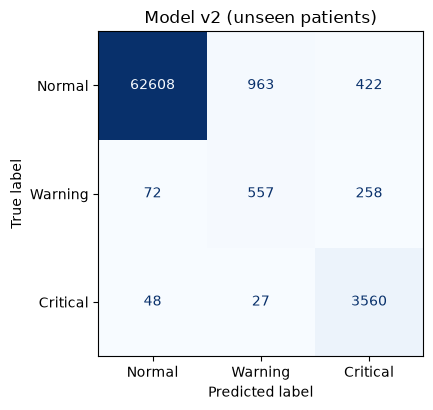

In [9]:
model, cols, threshold = fitted[CHOSEN]
test = test.assign(pred=predict_with_threshold(model, test[cols], threshold))
print(classification_report(test["status"], test["pred"], labels=list(LABELS), zero_division=0))
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay.from_predictions(test["status"], test["pred"], labels=list(LABELS), ax=ax, cmap="Blues", colorbar=False)
ax.set_title("Model v2 (unseen patients)")
fig.tight_layout()
fig.savefig(ROOT / "docs" / "results" / "model_v2_confusion.png", dpi=150)
plt.show()

In [10]:
import warnings
warnings.filterwarnings("ignore", message="y_pred contains classes not in y_true")  # a group with no Warning readings


def by(column):
    def one(d):
        s = scores(d["status"], d["pred"])
        return pd.Series({"patients": d["patient_id"].nunique(), "Critical readings": int((d["status"] == "Critical").sum()),
                          "recall Critical": s["recall Critical"], "false alarms /100 Normal": s["false alarms /100 Normal"]})
    return test.groupby(column).apply(one, include_groups=False).round(3)

test["risk_group"] = test["risk_level"].map({1: "Low", 2: "Medium", 3: "High"})
breakdowns = {c: by(c) for c in ["risk_group", "diabetic", "spo2_scale", "fault_type", "episode_type"]}
for column, table in breakdowns.items():
    print(f"\nBy {column}:\n{table.to_string()}")


By risk_group:
            patients  Critical readings  recall Critical  false alarms /100 Normal
risk_group                                                                        
High             6.0             2621.0            0.979                     1.198
Low              4.0               18.0            0.944                     0.177
Medium           6.0              996.0            0.982                     0.493

By diabetic:
          patients  Critical readings  recall Critical  false alarms /100 Normal
diabetic                                                                        
0             10.0              998.0            0.976                     0.481
1              6.0             2637.0            0.981                     0.982

By spo2_scale:
            patients  Critical readings  recall Critical  false alarms /100 Normal
spo2_scale                                                                        
1               14.0             2898.0          

## Step 7 · Why does it decide? (explainability)
**Permutation importance**: shuffle one input at a time on a sample of test readings and see how much recall for Critical drops. A big drop means the model relies on that input. For each alert, the dashboard can also show which vital signs scored points in the NEWS2-inspired rule (`src/labelling.score_parts`), so the clinician sees a reason, not just a label.

In [11]:
sample = test.sample(20000, random_state=SEED)
recall_critical = lambda est, X, y: scores(y, predict_with_threshold(est, X, threshold))["recall Critical"]  # noqa: E731
imp = permutation_importance(model, sample[cols], sample["status"], scoring=recall_critical,
                             n_repeats=3, random_state=SEED)
importance = pd.Series(imp.importances_mean, index=cols).sort_values(ascending=False).round(3)
print("Drop in recall for Critical when the input is shuffled:\n" + importance.head(10).to_string())

Drop in recall for Critical when the input is shuffled:
spo2_med5            0.432
heart_rate_med5      0.093
spo2_scale           0.055
systolic_bp_med5     0.042
heart_rate           0.039
systolic_bp          0.034
glucose_med5         0.028
spo2                 0.018
glucose              0.013
diastolic_bp_med5    0.004


## Step 8 · Save model v2
The model is saved compressed, with a description file that the API will read: its inputs (in order), labels, Critical threshold, window size, and its test results. `src/model.load` loads both.

In [12]:
MODEL_PATH = ROOT / "models" / "model_v2.joblib"
joblib.dump(model, MODEL_PATH, compress=3)
example = test.iloc[0]
info = {
    "name": "model_v2", "approach": CHOSEN, "created": str(date.today()),
    "features": cols, "labels": list(LABELS), "critical_threshold": threshold, "window": WINDOW,
    "needs": "clean_readings -> add_patient_settings -> add_window_features (src/features.py)",
    "trained_on": {"data": "data/sim_vitals.csv (simulator seed 42)", "patients": int(learn["patient_id"].nunique()),
                   "readings": int(len(learn))},
    "test": {"patients": int(test["patient_id"].nunique()),
             **{k: round(float(v), 4) for k, v in results.loc[CHOSEN, ["recall Critical", "false alarms /100 Normal",
                                                                     "precision Critical", "F1 (macro)"]].items()}},
    "example_row": {c: (None if pd.isna(example[c]) else float(example[c])) for c in cols},
}
MODEL_PATH.with_suffix(".json").write_text(json.dumps(info, indent=2))
print(f"Saved {MODEL_PATH.relative_to(ROOT)} ({MODEL_PATH.stat().st_size / 1e6:.1f} MB) and model_v2.json")

Saved models/model_v2.joblib (0.4 MB) and model_v2.json


## Step 9 · Write the results file

In [13]:
def md_table(frame):
    """A DataFrame as a Markdown table (index first)."""
    head = "| " + " | ".join([str(frame.index.name or "")] + [str(c) for c in frame.columns]) + " |"
    rule = "|---" * (len(frame.columns) + 1) + "|"
    body = ["| " + " | ".join([str(i)] + [str(v) for v in row]) + " |" for i, row in zip(frame.index, frame.to_numpy(), strict=True)]
    return "\n".join([head, rule, *body])


lines = [f"# Model comparison ({date.today():%d %b %Y})", "",
         "Notebook `02_compare_models.ipynb`. Data: `sim_vitals.csv` (simulator seed 42), cleaned as the API will clean it.",
         f"Trained on {learn['patient_id'].nunique()} patients; tested once on {test['patient_id'].nunique()} unseen patients "
         f"({len(test):,} readings), the same ones as notebook 01.",
         f"Thresholds tuned by 5-fold cross-validation on the training patients only, to recall {TUNING_TARGET} for Critical.", "",
         "## Unseen test patients", "", "| Approach | " + " | ".join(show) + " |", "|---" * (len(show) + 1) + "|"]
lines += [f"| {name} | " + " | ".join("" if pd.isna(r[c]) else str(r[c]) for c in show) + " |" for name, r in results.iterrows()]
lines += ["", f"**Chosen (on the training patients only): {CHOSEN}.** Target (A5): recall for Critical ≥ {RECALL_TARGET}, "
          f"≤ {FALSE_ALARM_CAP} false alarms per 100 Normal readings: " + ("met." if meets else "not met."), "",
          "## Cross-validated on the training patients", "", md_table(oof_table[["recall Critical", "false alarms /100 Normal", "precision Critical", "F1 (macro)"]]), ""]
for column, table in breakdowns.items():
    lines += [f"## Chosen model by {column}", "", md_table(table), ""]
lines += ["## What the chosen model relies on (permutation importance, drop in recall for Critical)", "",
          md_table(importance.head(10).to_frame("drop")), "", "Confusion matrix: `model_v2_confusion.png`."]
(ROOT / "docs" / "results" / "model_comparison.md").write_text("\n".join(lines) + "\n")
print("Written to docs/results/model_comparison.md")

Written to docs/results/model_comparison.md


## Step 10 · Your answers (for ADR 1, `docs/approaches.md` and the report)
1. Which approach did you choose, and why that one rather than the others? Use the numbers from Steps 4 and 5.
2. How close does the plain NEWS2-inspired rule come? If a rule does nearly as well, what does the machine learning model add, and what does it cost (explainability, size, energy)?
3. What did adding the last-5 median change, and what would the API need to keep for each patient to compute it in real time?
4. Does the model work as well for every group in Step 6? Which group is worst, and is that a model problem or a data problem (how many patients are in that group)?
5. Could this model run on the edge (a phone or gateway)? Look at its size and time per reading.

**Your answer:**

_(double-click to type)_